# Exploratory Data Analysis — India Oil Price, Exchange Rate & CPI

This notebook performs a **step-by-step EDA on each of the three raw source files** independently,
then analyses cross-variable relationships.

| # | Source | Publisher | Frequency |
|---|--------|-----------|----------|
| 1 | `Crude-Oil-Price-(Indian Basket)-Historical.xlsx` | PPAC, MoPNG, GoI | Monthly |
| 2 | `Exchange Rate...xlsx` | Reserve Bank of India (RBI) | Monthly |
| 3 | `r45_consumer_price_index.csv` | MOSPI, GoI | Monthly |

**Sections:**
1. Setup & Data Loading
2. EDA — Crude Oil Price (Indian Basket)
3. EDA — USD/INR Exchange Rate
4. EDA — Consumer Price Index (CPI)
5. Cross-Variable Analysis
6. Summary of Key Findings

---
## 0. Setup & Data Loading

In [1]:
import subprocess, sys
subprocess.check_call([sys.executable,'-m','pip','install',
                        'pandas','openpyxl','numpy','matplotlib','scipy','seaborn','-q'])

0

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
import warnings, os

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', '{:.4f}'.format)

# ── Style ──────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor': '#0d1117',
    'axes.facecolor':   '#161b22',
    'axes.edgecolor':   '#30363d',
    'axes.labelcolor':  '#c9d1d9',
    'xtick.color':      '#8b949e',
    'ytick.color':      '#8b949e',
    'text.color':       '#c9d1d9',
    'grid.color':       '#21262d',
    'grid.linestyle':   '--',
    'axes.titlecolor':  '#e6edf3',
    'axes.titlesize':   12,
    'axes.labelsize':   10,
    'legend.facecolor': '#161b22',
    'legend.edgecolor': '#30363d',
    'figure.titlesize': 14,
})

COLORS = {
    'oil':    '#f0a500',
    'fx':     '#a371f7',
    'cpi':    '#3fb950',
    'infl':   '#ff7b72',
    'pos':    '#3fb950',
    'neg':    '#f85149',
    'neutral':'#58a6ff',
}

OIL_FILE = 'Crude-Oil-Price-(Indian Basket)-Historical.xlsx'
FX_FILE  = 'Exchange Rate of the Indian Rupee vis-à-vis the SDR, US Dollar, Pound Sterling, Euro and Japanese Yen (Monthly Average and end-Month Rates).xlsx'
CPI_FILE = 'r45_consumer_price_index.csv'
OUT_DIR  = 'eda_outputs'
os.makedirs(OUT_DIR, exist_ok=True)

print('Setup complete.')

Setup complete.


### Load & Parse All Three Sources

We reuse the exact same parsing logic from `data_pipeline.ipynb` to get clean monthly time series.

In [3]:
# ── Oil price ─────────────────────────────────────────────────────────
oil_df = pd.read_excel(OIL_FILE, sheet_name='Sheet1', skiprows=10)
month_names = ['Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec','Jan','Feb','Mar']
oil_df.columns = ['fin_year'] + month_names + ['annual_avg','composition']
oil_df = oil_df[oil_df['fin_year'].astype(str).str.match(r'^\d{4}-\d{2,4}$')].copy()
oil_df = oil_df[['fin_year'] + month_names].reset_index(drop=True)

def fy_to_months(row):
    yr = int(str(row['fin_year']).split('-')[0])
    mm = [('Apr',4,yr),('May',5,yr),('Jun',6,yr),('Jul',7,yr),
          ('Aug',8,yr),('Sep',9,yr),('Oct',10,yr),('Nov',11,yr),
          ('Dec',12,yr),('Jan',1,yr+1),('Feb',2,yr+1),('Mar',3,yr+1)]
    out = []
    for mn,mo,y in mm:
        v = row[mn]
        if pd.notna(v):
            try: out.append({'date':pd.Timestamp(year=y,month=mo,day=1),'oil_price_usd_bbl':float(v)})
            except: pass
    return out

recs = []
for _,r in oil_df.iterrows(): recs.extend(fy_to_months(r))
oil = pd.DataFrame(recs).drop_duplicates('date').sort_values('date').set_index('date')

# ── Exchange rates ──────────────────────────────────────────────────────
fx_raw_all = pd.read_excel(FX_FILE, sheet_name=None, header=None)
sheet_name = list(fx_raw_all.keys())[0]
fx_df = pd.read_excel(FX_FILE, sheet_name=sheet_name, header=None, skiprows=8)
fx_df.columns = ['blank','date_raw','year_month','sdr_avg','sdr_end',
                  'usd_avg','usd_end','gbp_avg','gbp_end','jpy_avg','jpy_end','eur_avg','eur_end']
fx_df = fx_df[pd.to_datetime(fx_df['date_raw'], errors='coerce').notna()].copy()
fx_df['date'] = pd.to_datetime(fx_df['date_raw']).dt.to_period('M').dt.to_timestamp()
for col in ['usd_avg','sdr_avg','gbp_avg','jpy_avg','eur_avg']:
    fx_df[col] = pd.to_numeric(fx_df[col], errors='coerce')
fx = fx_df[['date','usd_avg','sdr_avg','gbp_avg','jpy_avg','eur_avg']].copy()
fx.columns = ['date','usd_inr','sdr_inr','gbp_inr','jpy_inr_per100','eur_inr']
fx = fx.dropna(subset=['usd_inr']).drop_duplicates('date').sort_values('date').set_index('date')

# ── CPI ────────────────────────────────────────────────────────────────
cpi_raw = pd.read_csv(CPI_FILE, encoding='utf-8', on_bad_lines='skip')
def parse_cpi_category(cat_name):
    sub = cpi_raw[cpi_raw['c2'].str.strip()==cat_name].copy()
    sub['date'] = pd.to_datetime(sub['c1'].str.strip(), format='%b-%Y', errors='coerce')
    sub = sub.dropna(subset=['date'])
    sub['date'] = sub['date'].dt.to_period('M').dt.to_timestamp()
    for c in ['c4','c5','c6','c7','c8','c9']:
        sub[c] = pd.to_numeric(sub[c], errors='coerce')
    return sub.drop_duplicates('date').sort_values('date').set_index('date')

cpi_gen  = parse_cpi_category('A) General Index')
cpi_food = parse_cpi_category('A.1) Food and beverages')
cpi_fuel = parse_cpi_category('A.5) Fuel and light')
cpi_misc = parse_cpi_category('A.6) Miscellaneous')
cpi_clth = parse_cpi_category('A.3) Clothing and footwear')

# Filter to 2014-2025 for EDA
EDA_START = '2014-01-01'
EDA_END   = '2025-12-01'

oil_e = oil.loc[EDA_START:EDA_END].copy()
fx_e  = fx.loc[EDA_START:EDA_END].copy()
cpi_e = cpi_gen.loc[EDA_START:EDA_END].copy()

print(f'Oil:  {len(oil)} total rows  |  {len(oil_e)} in 2014-2025')
print(f'FX:   {len(fx)} total rows   |  {len(fx_e)} in 2014-2025')
print(f'CPI:  {len(cpi_gen)} total rows  |  {len(cpi_e)} in 2014-2025')

Oil:  312 total rows  |  144 in 2014-2025
FX:   415 total rows   |  144 in 2014-2025
CPI:  156 total rows  |  144 in 2014-2025


---
## 1. EDA — Crude Oil Price (Indian Basket)

**What is this dataset?**  
The PPAC publishes monthly average FOB (Free On Board) prices of the Indian crude oil basket, which is a weighted blend of **Oman & Dubai** (sour grades) and **Brent Dated** (sweet grade). The blend ratio changes each financial year based on the previous year's refinery intake composition.

**Unit:** USD per barrel

In [4]:
# Basic statistics on the full historical series
print('=== Full historical oil price series ===')
print(f'Date range : {oil.index.min().date()}  to  {oil.index.max().date()}')
print(f'Total months: {len(oil)}')
print()
print(oil['oil_price_usd_bbl'].describe().rename('oil_price_usd_bbl').to_frame().T.to_string())
print()
print('=== 2014-2025 window ===')
print(oil_e['oil_price_usd_bbl'].describe().rename('oil_price_usd_bbl').to_frame().T.to_string())

=== Full historical oil price series ===
Date range : 2000-04-01  to  2026-03-01
Total months: 312

                     count    mean     std     min     25%     50%     75%      max
oil_price_usd_bbl 312.0000 66.0390 27.6628 18.2400 44.3362 65.2396 83.8370 132.4712

=== 2014-2025 window ===
                     count    mean     std     min     25%     50%     75%      max
oil_price_usd_bbl 144.0000 68.2768 19.8693 19.9017 54.6013 67.0066 80.4357 116.0114


### 1.1 Full Historical Price Series

Plotting the complete monthly oil price timeline to identify major structural regimes and events.

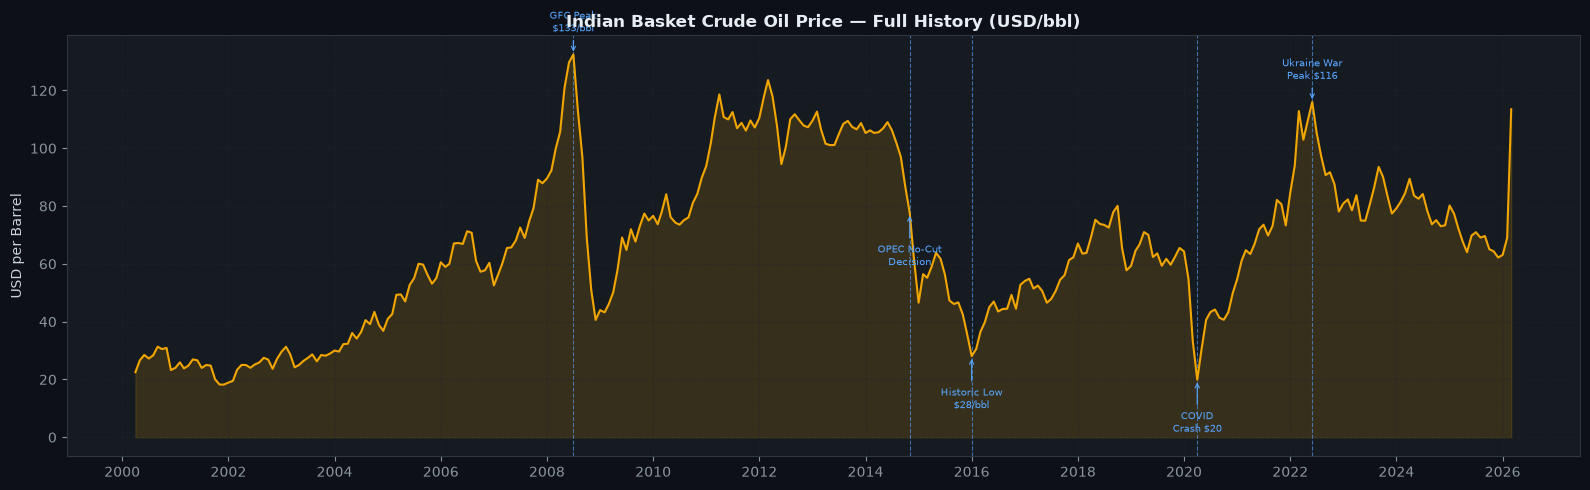

In [5]:
# Key global events that moved oil prices significantly
events = [
    ('2008-07-01', 'GFC Peak\n$133/bbl',   'top'),
    ('2014-11-01', 'OPEC No-Cut\nDecision', 'bottom'),
    ('2016-01-01', 'Historic Low\n$28/bbl', 'bottom'),
    ('2020-04-01', 'COVID\nCrash $20',      'bottom'),
    ('2022-06-01', 'Ukraine War\nPeak $116', 'top'),
]

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(oil.index, oil['oil_price_usd_bbl'], color=COLORS['oil'], lw=1.5, zorder=3)
ax.fill_between(oil.index, oil['oil_price_usd_bbl'], alpha=0.15, color=COLORS['oil'])

for date_str, label, pos in events:
    dt = pd.Timestamp(date_str)
    if dt in oil.index:
        val = oil.loc[dt,'oil_price_usd_bbl']
        ax.axvline(dt, color='#58a6ff', lw=0.8, ls='--', alpha=0.6)
        y_off = 8 if pos=='top' else -18
        ax.annotate(label, xy=(dt,val), xytext=(dt, val+y_off),
                    fontsize=7.5, color='#58a6ff', ha='center',
                    arrowprops=dict(arrowstyle='->', color='#58a6ff', lw=0.8))

ax.set_title('Indian Basket Crude Oil Price — Full History (USD/bbl)', fontweight='bold')
ax.set_ylabel('USD per Barrel')
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/oil_01_full_history.png', dpi=150, bbox_inches='tight')
plt.show()

### 1.2 Distribution of Monthly Prices (2014–2025)

Understanding the shape of the price distribution — is it symmetric, skewed, bimodal?
This matters for choosing appropriate statistical models downstream.

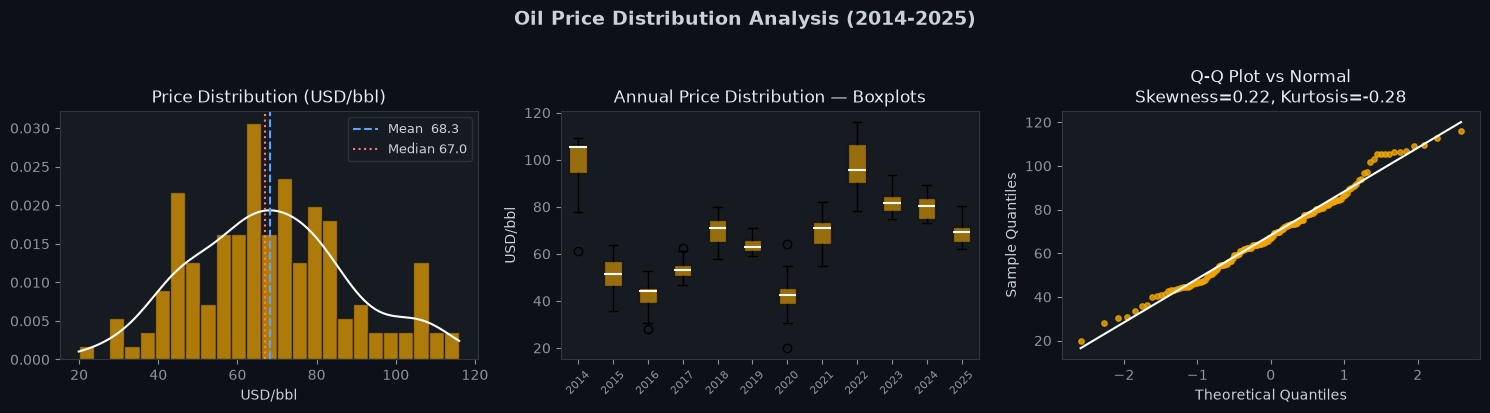

Skewness : 0.219  (>0 = right-tail; <0 = left-tail)
Kurtosis : -0.277  (>0 = heavier tails than normal)


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

vals = oil_e['oil_price_usd_bbl'].dropna()

# Histogram + KDE
ax = axes[0]
ax.hist(vals, bins=25, color=COLORS['oil'], alpha=0.7, edgecolor='#0d1117', density=True)
from scipy.stats import gaussian_kde
kde = gaussian_kde(vals)
xs  = np.linspace(vals.min(), vals.max(), 200)
ax.plot(xs, kde(xs), color='white', lw=1.5)
ax.axvline(vals.mean(),   color='#58a6ff', lw=1.5, ls='--', label=f'Mean  {vals.mean():.1f}')
ax.axvline(vals.median(), color='#ff7b72', lw=1.5, ls=':',  label=f'Median {vals.median():.1f}')
ax.set_title('Price Distribution (USD/bbl)'); ax.set_xlabel('USD/bbl')
ax.legend(fontsize=9)

# Boxplot by year
ax = axes[1]
oil_e['year'] = oil_e.index.year
years = sorted(oil_e['year'].unique())
data_by_year = [oil_e.loc[oil_e['year']==y,'oil_price_usd_bbl'].values for y in years]
bp = ax.boxplot(data_by_year, patch_artist=True, medianprops=dict(color='white',lw=1.5))
for patch in bp['boxes']: patch.set(facecolor=COLORS['oil'], alpha=0.6)
ax.set_xticks(range(1,len(years)+1)); ax.set_xticklabels(years, rotation=45, fontsize=8)
ax.set_title('Annual Price Distribution — Boxplots'); ax.set_ylabel('USD/bbl')

# Q-Q Plot vs Normal
ax = axes[2]
(osm, osr), (slope, intercept, _) = stats.probplot(vals, dist='norm')
ax.scatter(osm, osr, color=COLORS['oil'], s=15, alpha=0.8)
ax.plot(osm, slope*np.array(osm)+intercept, color='white', lw=1.5)
skew = vals.skew(); kurt = vals.kurt()
ax.set_title(f'Q-Q Plot vs Normal\nSkewness={skew:.2f}, Kurtosis={kurt:.2f}')
ax.set_xlabel('Theoretical Quantiles'); ax.set_ylabel('Sample Quantiles')

plt.suptitle('Oil Price Distribution Analysis (2014-2025)', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/oil_02_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Skewness : {skew:.3f}  (>0 = right-tail; <0 = left-tail)')
print(f'Kurtosis : {kurt:.3f}  (>0 = heavier tails than normal)')

### 1.3 Monthly Returns & Volatility

Month-over-month log returns reveal the **speed and magnitude** of price changes.
Rolling volatility (3-month std dev of log returns) measures *risk* — how uncertain prices have been recently.

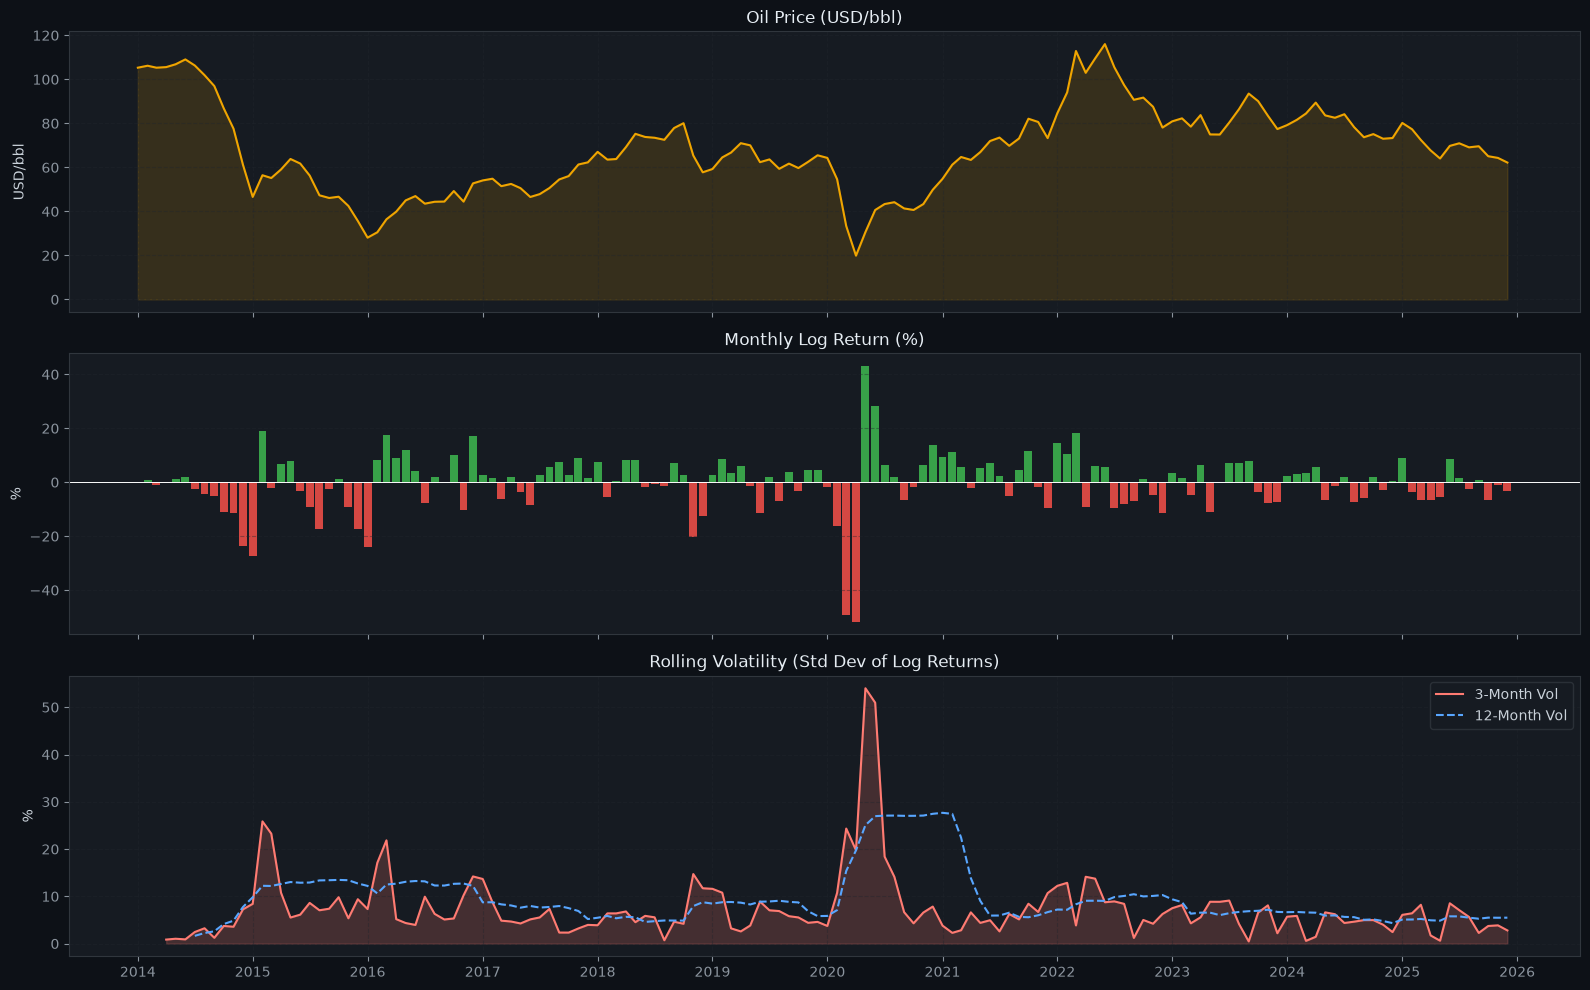

Largest single-month drawdowns:
            log_return_%
date                    
2020-04-01      -51.6515
2020-03-01      -49.3215
2015-01-01      -27.3015
2016-01-01      -23.9600
2014-12-01      -23.7000

Largest single-month rallies:
            log_return_%
date                    
2020-05-01       43.0377
2020-06-01       28.3421
2015-02-01       19.1694
2022-03-01       18.2264
2016-03-01       17.6589


In [7]:
oil_e = oil_e.copy()
oil_e['log_ret']   = np.log(oil_e['oil_price_usd_bbl']/oil_e['oil_price_usd_bbl'].shift(1))*100
oil_e['vol_3m']    = oil_e['log_ret'].rolling(3, min_periods=3).std(ddof=1)
oil_e['vol_12m']   = oil_e['log_ret'].rolling(12, min_periods=6).std(ddof=1)

fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)

# Price
ax = axes[0]
ax.plot(oil_e.index, oil_e['oil_price_usd_bbl'], color=COLORS['oil'], lw=1.5)
ax.fill_between(oil_e.index, oil_e['oil_price_usd_bbl'], alpha=0.15, color=COLORS['oil'])
ax.set_ylabel('USD/bbl'); ax.set_title('Oil Price (USD/bbl)')
ax.grid(True, alpha=0.4)

# Log returns
ax = axes[1]
cols = [COLORS['neg'] if v<0 else COLORS['pos'] for v in oil_e['log_ret'].fillna(0)]
ax.bar(oil_e.index, oil_e['log_ret'], width=25, color=cols, alpha=0.85)
ax.axhline(0, color='white', lw=0.7)
ax.set_ylabel('%'); ax.set_title('Monthly Log Return (%)')
ax.grid(True, alpha=0.4, axis='y')

# Volatility
ax = axes[2]
ax.plot(oil_e.index, oil_e['vol_3m'],  color='#ff7b72', lw=1.5, label='3-Month Vol')
ax.plot(oil_e.index, oil_e['vol_12m'], color='#58a6ff', lw=1.5, ls='--', label='12-Month Vol')
ax.fill_between(oil_e.index, oil_e['vol_3m'], alpha=0.2, color='#ff7b72')
ax.set_ylabel('%'); ax.set_title('Rolling Volatility (Std Dev of Log Returns)')
ax.legend(); ax.grid(True, alpha=0.4)

for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/oil_03_returns_volatility.png', dpi=150, bbox_inches='tight')
plt.show()

print('Largest single-month drawdowns:')
print(oil_e['log_ret'].nsmallest(5).rename('log_return_%').to_frame())
print('\nLargest single-month rallies:')
print(oil_e['log_ret'].nlargest(5).rename('log_return_%').to_frame())

### 1.4 Seasonal Pattern — Average Price by Calendar Month

Does crude oil price have a consistent seasonal cycle? We compute the average price
for each calendar month across all years (2014–2025) to identify any recurring patterns.
Seasonality in oil prices can stem from demand cycles (winter heating, summer driving),
OPEC meeting schedules, and refinery maintenance seasons.

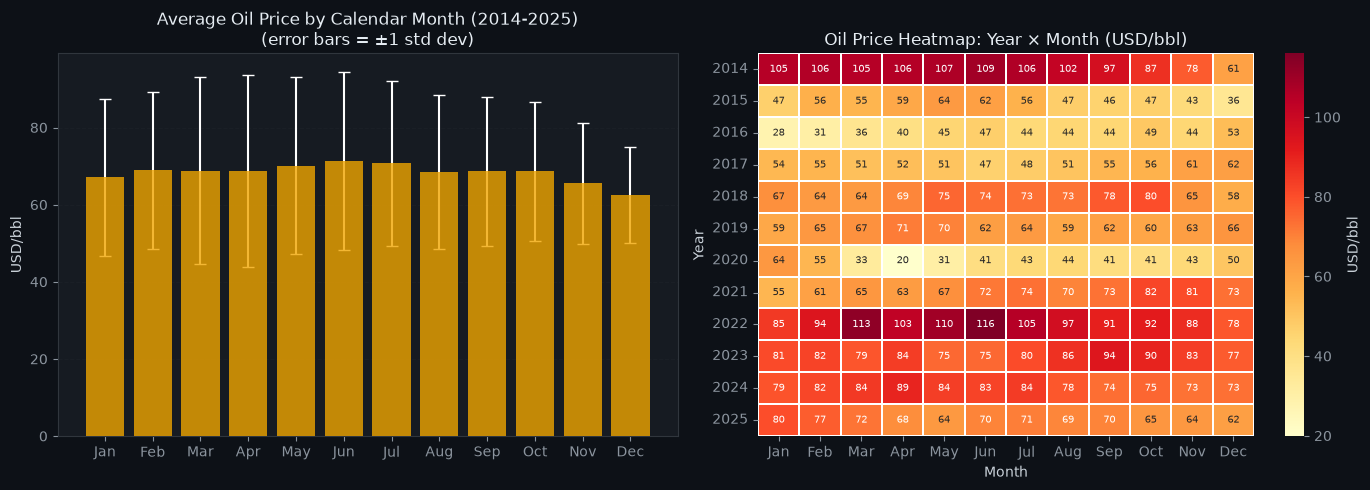

In [8]:
oil_e['month']     = oil_e.index.month
oil_e['month_name']= oil_e.index.strftime('%b')

monthly_avg = oil_e.groupby('month')['oil_price_usd_bbl'].agg(['mean','std','median'])
month_labels = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Average price by month
ax = axes[0]
bars = ax.bar(range(1,13), monthly_avg['mean'], color=COLORS['oil'], alpha=0.8, zorder=3)
ax.errorbar(range(1,13), monthly_avg['mean'], yerr=monthly_avg['std'],
            fmt='none', color='white', capsize=4, lw=1.5)
ax.set_xticks(range(1,13)); ax.set_xticklabels(month_labels)
ax.set_title('Average Oil Price by Calendar Month (2014-2025)\n(error bars = ±1 std dev)')
ax.set_ylabel('USD/bbl'); ax.grid(True, alpha=0.4, axis='y')

# Heatmap: year x month prices
ax = axes[1]
pivot = oil_e.pivot_table(values='oil_price_usd_bbl', index='year', columns='month', aggfunc='mean')
pivot.columns = month_labels
sns.heatmap(pivot, ax=ax, cmap='YlOrRd', annot=True, fmt='.0f', linewidths=0.3,
            annot_kws={'size':7}, cbar_kws={'label':'USD/bbl'})
ax.set_title('Oil Price Heatmap: Year × Month (USD/bbl)')
ax.set_xlabel('Month'); ax.set_ylabel('Year')

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/oil_04_seasonality.png', dpi=150, bbox_inches='tight')
plt.show()

### 1.5 Financial Year Averages & YoY Change

PPAC publishes data by Indian financial year (Apr–Mar). Looking at FY-level averages
gives a cleaner policy-relevant view, as India's oil import budget and subsidy calculations
use FY averages.

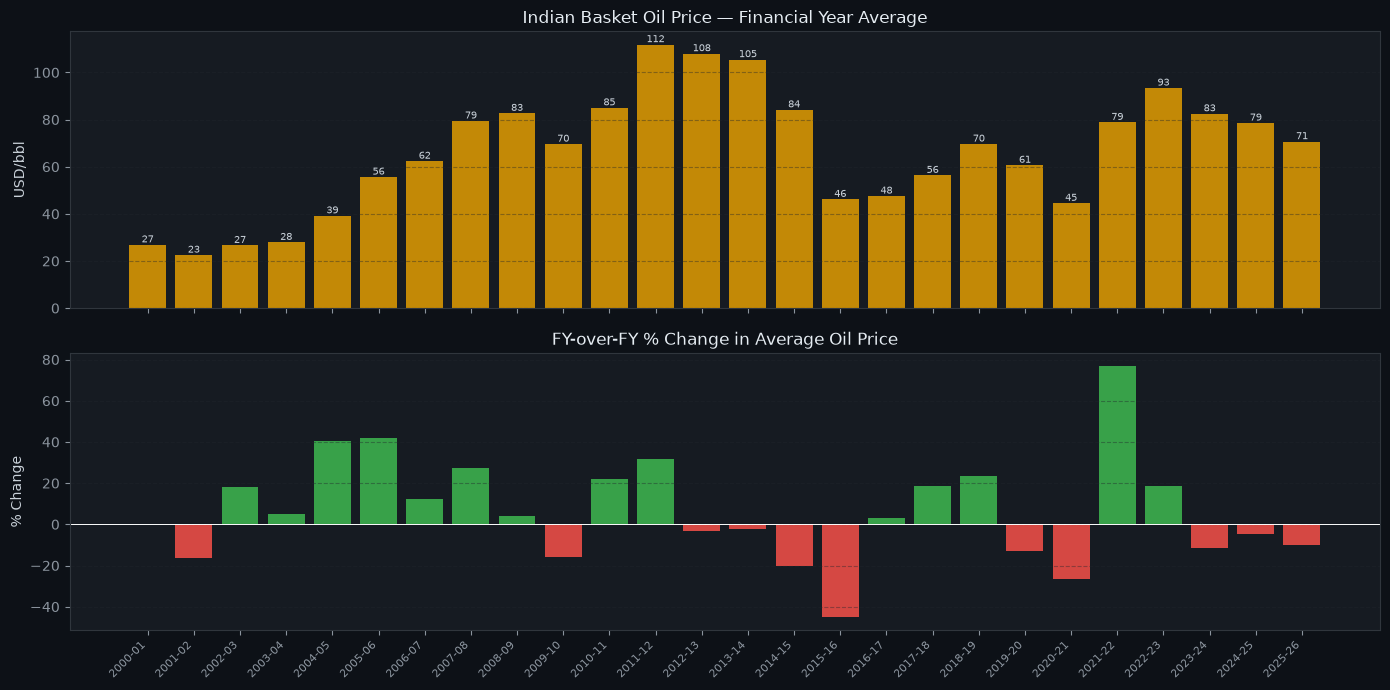

     FY  avg_price_usd_bbl  yoy_change_pct
2014-15            84.2020        -20.1870
2015-16            46.1879        -45.1462
2016-17            47.5907          3.0370
2017-18            56.3906         18.4908
2018-19            69.6650         23.5402
2019-20            60.6769        -12.9019
2020-21            44.5510        -26.5767
2021-22            78.8716         77.0368
2022-23            93.4314         18.4601
2023-24            82.5234        -11.6749
2024-25            78.5999         -4.7544
2025-26            70.6981        -10.0532


In [9]:
# Assign financial year: Apr-Mar
oil_full = oil.copy()
oil_full['fy_start'] = oil_full.index.year.where(oil_full.index.month >= 4,
                                                   oil_full.index.year - 1)
oil_full['fy_label'] = oil_full['fy_start'].astype(str) + '-' + \
                       (oil_full['fy_start']+1).astype(str).str[-2:]

fy_avg = oil_full.groupby('fy_label')['oil_price_usd_bbl'].mean().reset_index()
fy_avg.columns = ['FY','avg_price_usd_bbl']
fy_avg['yoy_change_pct'] = fy_avg['avg_price_usd_bbl'].pct_change()*100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

ax1.bar(fy_avg['FY'], fy_avg['avg_price_usd_bbl'], color=COLORS['oil'], alpha=0.8)
ax1.set_ylabel('USD/bbl'); ax1.set_title('Indian Basket Oil Price — Financial Year Average')
ax1.grid(True, alpha=0.4, axis='y')
for i,(fy,v) in enumerate(zip(fy_avg['FY'], fy_avg['avg_price_usd_bbl'])):
    ax1.text(i, v+1, f'{v:.0f}', ha='center', fontsize=7, color='#c9d1d9')

yoy_colors = [COLORS['pos'] if v>=0 else COLORS['neg'] for v in fy_avg['yoy_change_pct'].fillna(0)]
ax2.bar(fy_avg['FY'], fy_avg['yoy_change_pct'], color=yoy_colors, alpha=0.85)
ax2.axhline(0, color='white', lw=0.7)
ax2.set_ylabel('% Change'); ax2.set_title('FY-over-FY % Change in Average Oil Price')
ax2.grid(True, alpha=0.4, axis='y')

plt.xticks(rotation=45, ha='right', fontsize=8)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/oil_05_fy_averages.png', dpi=150, bbox_inches='tight')
plt.show()

print(fy_avg.tail(12).to_string(index=False))

---
## 2. EDA — USD/INR Exchange Rate

**What is this dataset?**  
Monthly average and end-month exchange rates published by the RBI for five currency pairs:
SDR, US Dollar, British Pound Sterling, Japanese Yen (per 100 JPY), and Euro — all in Indian Rupees.

**Why it matters for oil:** India imports ~85% of its crude oil, priced in USD.
A weaker rupee directly raises the domestic cost of oil imports, amplifying price pressures
even when the USD price is stable.

In [10]:
print('=== FX Dataset Overview ===')
print(f'Date range : {fx.index.min().date()} to {fx.index.max().date()}')
print(f'Total months: {len(fx)}')
print()
print('=== USD/INR 2014-2025 Summary ===')
print(fx_e['usd_inr'].describe().to_frame().T.to_string())
print()
print('All currencies available:')
print(fx.columns.tolist())

=== FX Dataset Overview ===
Date range : 1992-03-01 to 2026-09-01
Total months: 415

=== USD/INR 2014-2025 Summary ===
           count    mean    std     min     25%     50%     75%     max
usd_inr 144.0000 73.0298 8.2644 59.3050 66.1926 72.0348 82.0536 90.0913

All currencies available:
['usd_inr', 'sdr_inr', 'gbp_inr', 'jpy_inr_per100', 'eur_inr']


### 2.1 USD/INR Trend & Depreciation Rate

The INR has shown a **structural depreciation trend** against the USD over the past decade.
We decompose this into the price level (absolute rate) and the monthly rate of change
to distinguish structural drift from episodic volatility.

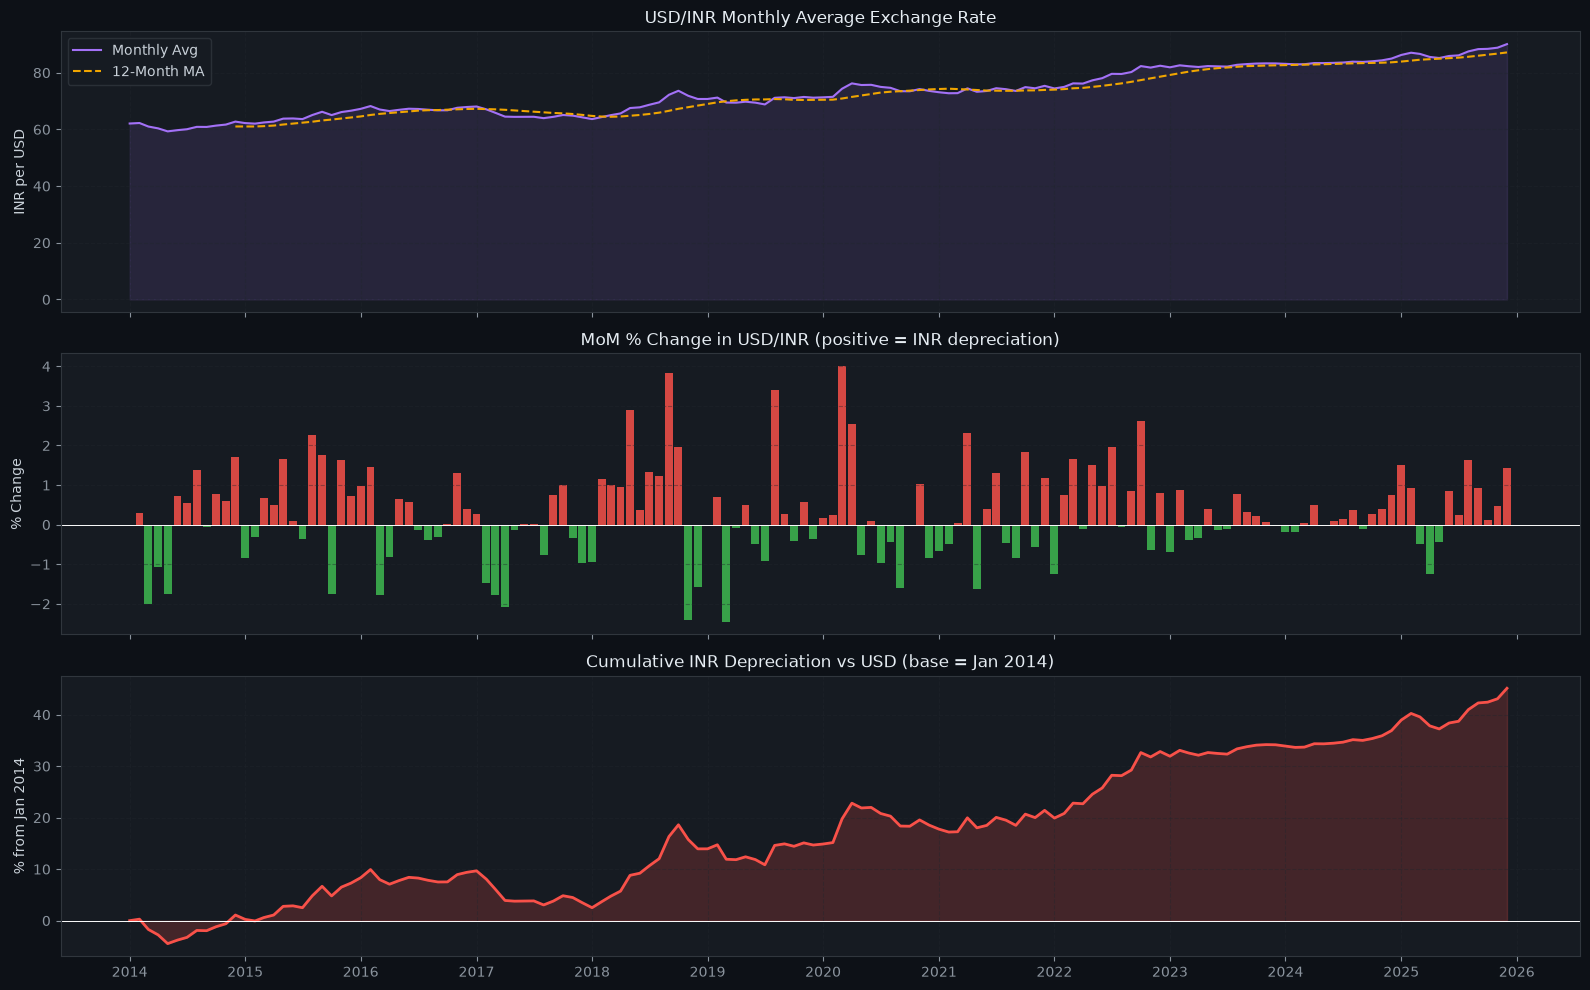

Total INR depreciation Jan-2014 to Dec-2025: 45.1%
Annualised depreciation rate               : 3.18% per year


In [11]:
fx_e = fx_e.copy()
fx_e['usd_pct_change'] = fx_e['usd_inr'].pct_change()*100
fx_e['usd_12m_ma']     = fx_e['usd_inr'].rolling(12).mean()
fx_e['cum_depreciation'] = (fx_e['usd_inr']/fx_e['usd_inr'].iloc[0]-1)*100

fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)

ax = axes[0]
ax.plot(fx_e.index, fx_e['usd_inr'],    color=COLORS['fx'],    lw=1.5, label='Monthly Avg')
ax.plot(fx_e.index, fx_e['usd_12m_ma'], color='#f0a500', lw=1.5, ls='--', label='12-Month MA')
ax.fill_between(fx_e.index, fx_e['usd_inr'], alpha=0.12, color=COLORS['fx'])
ax.set_ylabel('INR per USD'); ax.set_title('USD/INR Monthly Average Exchange Rate')
ax.legend(); ax.grid(True, alpha=0.4)

ax = axes[1]
c2 = [COLORS['neg'] if v>0 else COLORS['pos'] for v in fx_e['usd_pct_change'].fillna(0)]
ax.bar(fx_e.index, fx_e['usd_pct_change'], width=25, color=c2, alpha=0.85)
ax.axhline(0, color='white', lw=0.7)
ax.set_ylabel('% Change'); ax.set_title('MoM % Change in USD/INR (positive = INR depreciation)')
ax.grid(True, alpha=0.4, axis='y')

ax = axes[2]
ax.plot(fx_e.index, fx_e['cum_depreciation'], color=COLORS['neg'], lw=2)
ax.fill_between(fx_e.index, fx_e['cum_depreciation'], alpha=0.2, color=COLORS['neg'])
ax.axhline(0, color='white', lw=0.7)
ax.set_ylabel('% from Jan 2014'); ax.set_title('Cumulative INR Depreciation vs USD (base = Jan 2014)')
ax.grid(True, alpha=0.4)

for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fx_01_usd_inr_trend.png', dpi=150, bbox_inches='tight')
plt.show()

total_dep = fx_e['cum_depreciation'].iloc[-1]
n_years   = (fx_e.index[-1]-fx_e.index[0]).days/365.25
ann_dep   = ((fx_e['usd_inr'].iloc[-1]/fx_e['usd_inr'].iloc[0])**(1/n_years)-1)*100
print(f'Total INR depreciation Jan-2014 to Dec-2025: {total_dep:.1f}%')
print(f'Annualised depreciation rate               : {ann_dep:.2f}% per year')

### 2.2 All Currency Pairs — Comparative View

The RBI dataset includes INR rates against 5 currencies. Normalising each to 100 at Jan 2014
allows a direct comparison of INR strength/weakness across different currency bases.

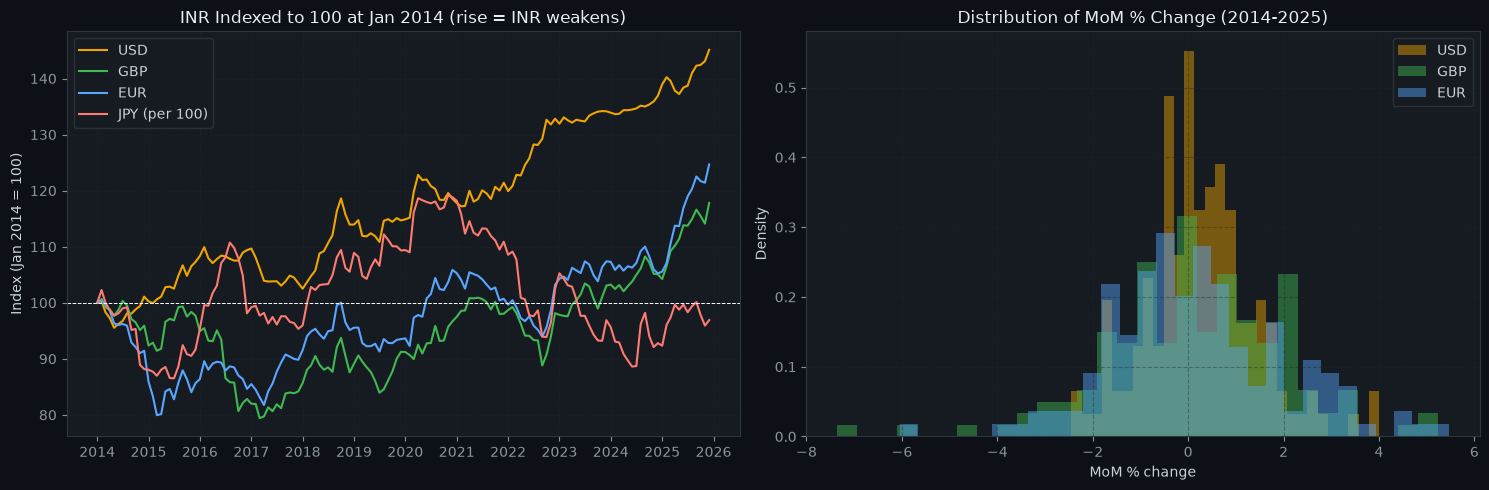

In [12]:
# Normalise all to 100 at Jan 2014
fx_norm = fx_e[['usd_inr','gbp_inr','eur_inr','jpy_inr_per100']].copy().dropna()
base = fx_norm.iloc[0]
fx_norm_idx = (fx_norm / base) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

palette = {'usd_inr':'#f0a500','gbp_inr':'#3fb950','eur_inr':'#58a6ff','jpy_inr_per100':'#ff7b72'}
labels  = {'usd_inr':'USD','gbp_inr':'GBP','eur_inr':'EUR','jpy_inr_per100':'JPY (per 100)'}

for col in fx_norm_idx.columns:
    ax1.plot(fx_norm_idx.index, fx_norm_idx[col], color=palette[col], lw=1.5, label=labels[col])
ax1.axhline(100, color='white', lw=0.7, ls='--')
ax1.set_title('INR Indexed to 100 at Jan 2014 (rise = INR weakens)')
ax1.set_ylabel('Index (Jan 2014 = 100)'); ax1.legend(); ax1.grid(True, alpha=0.4)
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Distribution of MoM changes
fx_e['gbp_pct'] = fx_e['gbp_inr'].pct_change()*100
fx_e['eur_pct'] = fx_e['eur_inr'].pct_change()*100
for col, color, label in [
    ('usd_pct_change', '#f0a500', 'USD'),
    ('gbp_pct',        '#3fb950', 'GBP'),
    ('eur_pct',        '#58a6ff', 'EUR'),
]:
    vals2 = fx_e[col].dropna()
    ax2.hist(vals2, bins=30, alpha=0.45, color=color, label=label, density=True)
ax2.set_title('Distribution of MoM % Change (2014-2025)')
ax2.set_xlabel('MoM % change'); ax2.set_ylabel('Density'); ax2.legend()
ax2.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fx_02_currencies_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

### 2.3 Exchange Rate Volatility & Stress Periods

Periods of high exchange rate volatility indicate **FX stress** — often linked to BoP pressures,
global risk-off episodes, or oil price shocks that worsen India's current account.

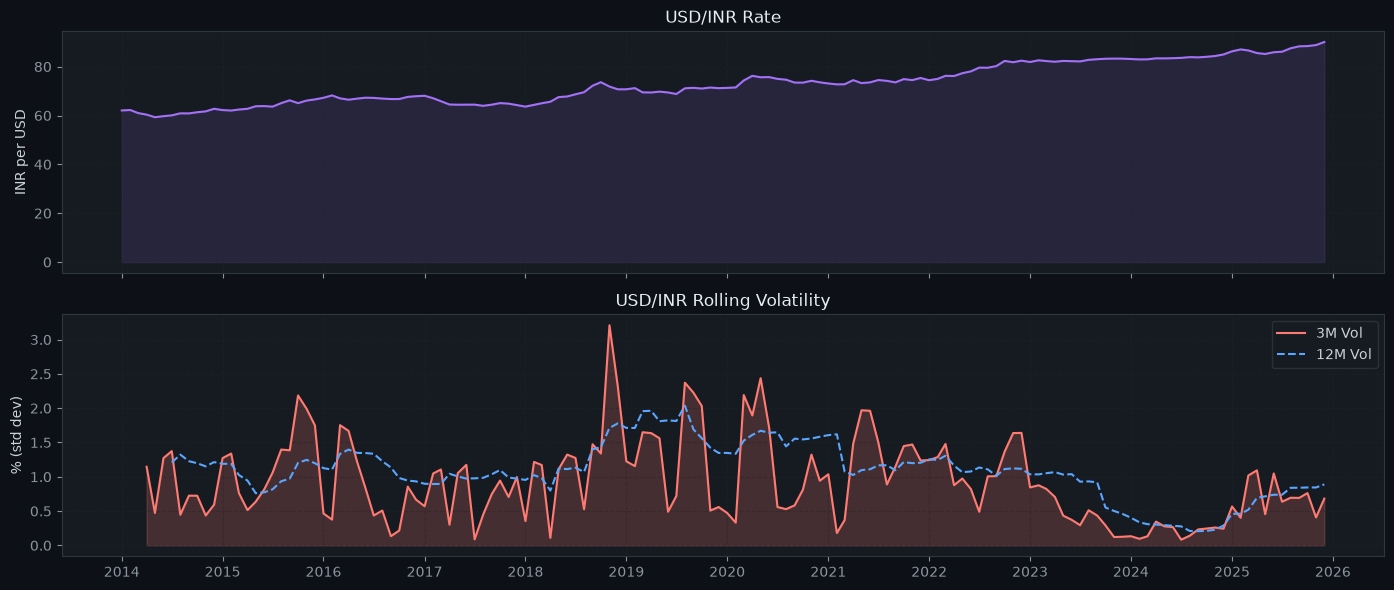

In [13]:
fx_e['vol_3m_fx']  = fx_e['usd_pct_change'].rolling(3, min_periods=3).std(ddof=1)
fx_e['vol_12m_fx'] = fx_e['usd_pct_change'].rolling(12, min_periods=6).std(ddof=1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

ax1.plot(fx_e.index, fx_e['usd_inr'], color=COLORS['fx'], lw=1.5)
ax1.fill_between(fx_e.index, fx_e['usd_inr'], alpha=0.12, color=COLORS['fx'])
ax1.set_ylabel('INR per USD'); ax1.set_title('USD/INR Rate')
ax1.grid(True, alpha=0.4)

ax2.plot(fx_e.index, fx_e['vol_3m_fx'],  color='#ff7b72', lw=1.5, label='3M Vol')
ax2.plot(fx_e.index, fx_e['vol_12m_fx'], color='#58a6ff', lw=1.5, ls='--', label='12M Vol')
ax2.fill_between(fx_e.index, fx_e['vol_3m_fx'], alpha=0.2, color='#ff7b72')
ax2.set_ylabel('% (std dev)'); ax2.set_title('USD/INR Rolling Volatility')
ax2.legend(); ax2.grid(True, alpha=0.4)

for ax in [ax1,ax2]:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fx_03_volatility.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 3. EDA — Consumer Price Index (CPI)

**What is this dataset?**  
India's CPI (2012=100), published monthly by MOSPI (National Statistical Office). It covers:
- **Rural and Urban** indices separately, and a **Combined (All-India)** weighted index
- **Basket categories:** Food & Beverages (~46% weight), Fuel & Light, Clothing, Housing (urban only), Miscellaneous

The **General Index** (category `A) General Index`) is the headline CPI used by the RBI for
its Flexible Inflation Targeting (FIT) framework — target: 4% ± 2%.

In [14]:
print('=== CPI General Index — 2014-2025 ===')
cpi_summary = pd.DataFrame({
    'combined_index':  cpi_e['c8'].describe(),
    'combined_yoy_pct':cpi_e['c9'].describe(),
    'rural_index':     cpi_e['c4'].describe(),
    'urban_index':     cpi_e['c6'].describe(),
})
print(cpi_summary.round(3).to_string())

=== CPI General Index — 2014-2025 ===
       combined_index  combined_yoy_pct  rural_index  urban_index
count        144.0000          144.0000     144.0000     144.0000
mean         153.3900            4.9070     154.7810     151.7890
std           25.8920            1.6990      26.0180      25.7720
min          113.6000            0.2500     114.0000     112.9000
25%          131.1000            3.6800     133.2250     128.5750
50%          148.8500            5.0050     150.1500     147.5000
75%          176.5500            6.0250     177.8250     175.0750
max          198.0000            8.6000     199.9000     195.9000


### 3.1 Headline CPI Trend — Combined, Rural & Urban

India shows a persistent **urban-rural CPI gap**: rural CPI is often driven more by food prices
(which have higher weight in the rural basket), while urban CPI is more influenced by services and housing.

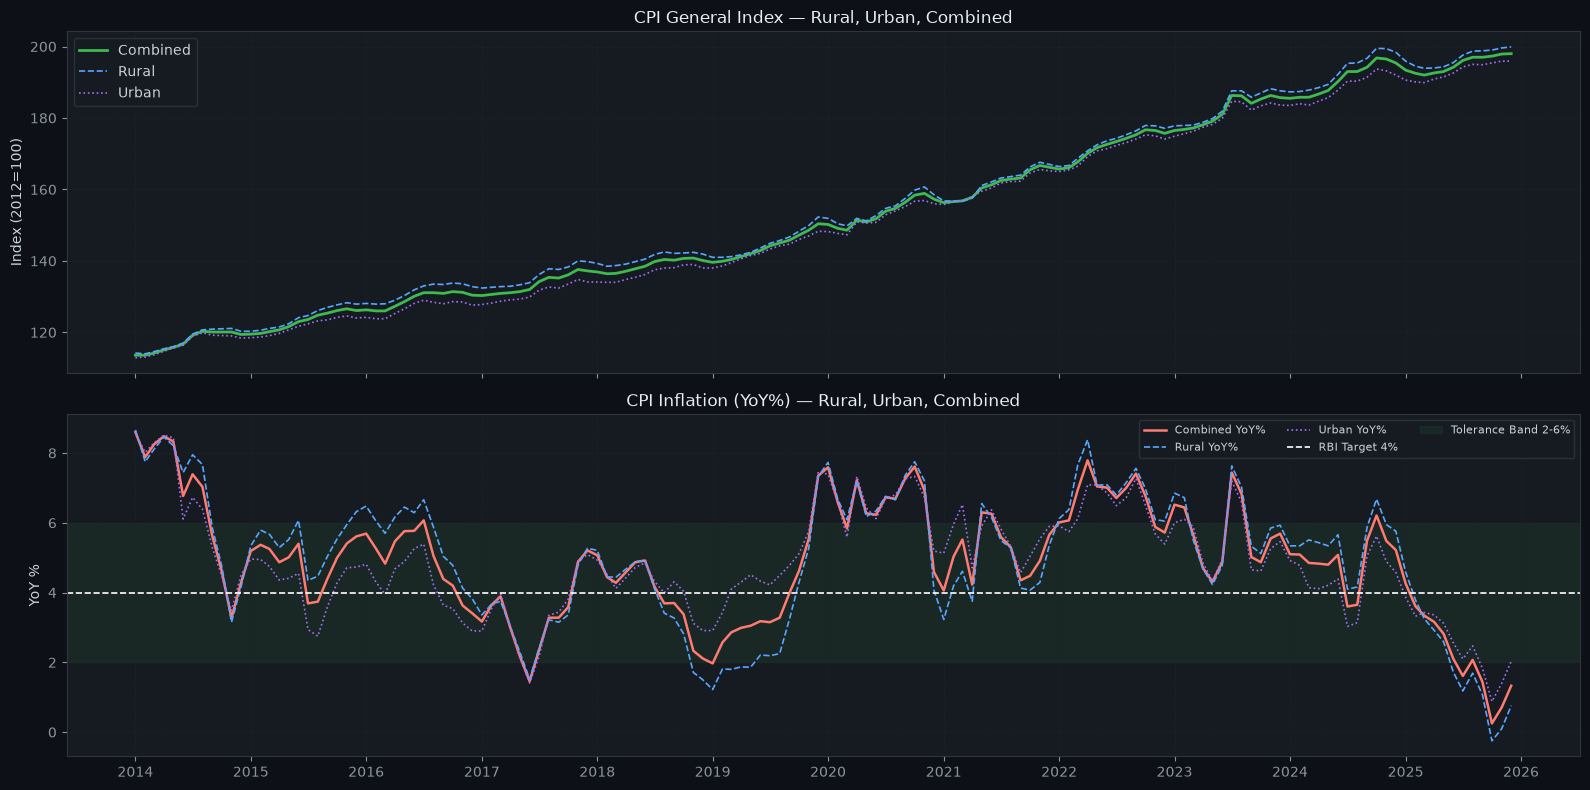

Months above RBI 4% target     : 102/144 (70.8%)
Months above 6% upper tolerance: 37/144 (25.7%)
Months below 2% lower tolerance: 7/144 (4.9%)


In [15]:
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

ax = axes[0]
ax.plot(cpi_e.index, cpi_e['c8'], color=COLORS['cpi'],     lw=2,   label='Combined')
ax.plot(cpi_e.index, cpi_e['c4'], color='#58a6ff',          lw=1.2, ls='--', label='Rural')
ax.plot(cpi_e.index, cpi_e['c6'], color='#a371f7',          lw=1.2, ls=':',  label='Urban')
ax.set_ylabel('Index (2012=100)'); ax.set_title('CPI General Index — Rural, Urban, Combined')
ax.legend(); ax.grid(True, alpha=0.4)

ax = axes[1]
ax.plot(cpi_e.index, cpi_e['c9'],  color=COLORS['infl'],   lw=1.8, label='Combined YoY%')
ax.plot(cpi_e.index, cpi_e['c5'],  color='#58a6ff',         lw=1.2, ls='--', label='Rural YoY%')
ax.plot(cpi_e.index, cpi_e['c7'],  color='#a371f7',         lw=1.2, ls=':',  label='Urban YoY%')
ax.axhline(4, color='white',   lw=1.2, ls='--', label='RBI Target 4%')
ax.axhspan(2, 6, alpha=0.08, color='#3fb950', label='Tolerance Band 2-6%')
ax.set_ylabel('YoY %'); ax.set_title('CPI Inflation (YoY%) — Rural, Urban, Combined')
ax.legend(ncols=3, fontsize=8); ax.grid(True, alpha=0.4)

for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/cpi_01_headline_trend.png', dpi=150, bbox_inches='tight')
plt.show()

above_target = (cpi_e['c9'] > 4).sum()
above_upper  = (cpi_e['c9'] > 6).sum()
below_lower  = (cpi_e['c9'] < 2).sum()
total = cpi_e['c9'].dropna().__len__()
print(f'Months above RBI 4% target     : {above_target}/{total} ({100*above_target/total:.1f}%)')
print(f'Months above 6% upper tolerance: {above_upper}/{total} ({100*above_upper/total:.1f}%)')
print(f'Months below 2% lower tolerance: {below_lower}/{total} ({100*below_lower/total:.1f}%)')

### 3.2 CPI Component Breakdown

Breaking CPI into its major sub-categories reveals **which components drive headline inflation**.
Food typically dominates India's CPI volatility due to monsoon dependency and supply-chain fragility.

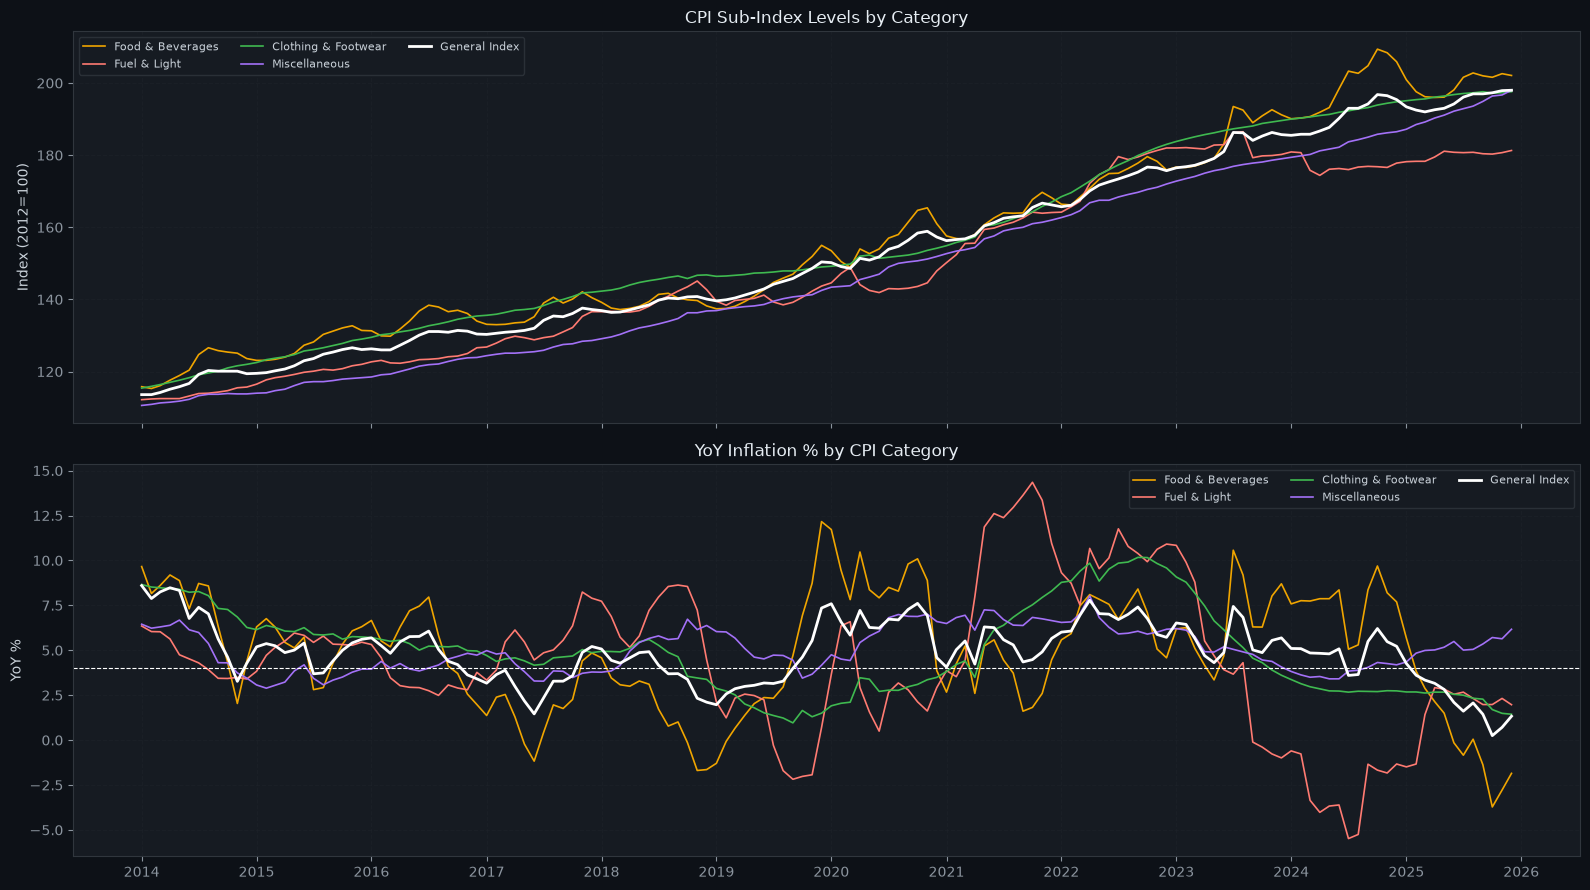

In [16]:
# Build combined YoY% for key categories over 2014-2025
cats = {
    'Food & Beverages': cpi_food,
    'Fuel & Light':     cpi_fuel,
    'Clothing & Footwear': cpi_clth,
    'Miscellaneous':    cpi_misc,
    'General Index':    cpi_gen,
}
cat_colors = ['#f0a500','#ff7b72','#3fb950','#a371f7','white']

fig, axes = plt.subplots(2,1, figsize=(16, 9), sharex=True)

# Combined index level
ax = axes[0]
for (name, df_cat), color in zip(cats.items(), cat_colors):
    s = df_cat.loc[EDA_START:EDA_END, 'c8'].dropna()
    lw = 2 if name=='General Index' else 1.2
    ax.plot(s.index, s, color=color, lw=lw, label=name)
ax.set_ylabel('Index (2012=100)'); ax.set_title('CPI Sub-Index Levels by Category')
ax.legend(ncols=3, fontsize=8); ax.grid(True, alpha=0.4)

# YoY inflation by category
ax = axes[1]
for (name, df_cat), color in zip(cats.items(), cat_colors):
    s = df_cat.loc[EDA_START:EDA_END, 'c9'].dropna()
    lw = 2 if name=='General Index' else 1.2
    ax.plot(s.index, s, color=color, lw=lw, label=name)
ax.axhline(4, color='white', lw=0.8, ls='--')
ax.set_ylabel('YoY %'); ax.set_title('YoY Inflation % by CPI Category')
ax.legend(ncols=3, fontsize=8); ax.grid(True, alpha=0.4)

for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/cpi_02_components.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.3 Inflation Distribution & RBI Target Analysis

How well has India's inflation stayed within the RBI's Flexible Inflation Target of **4% ± 2%**?
We visualise the distribution of monthly inflation readings against the tolerance band.

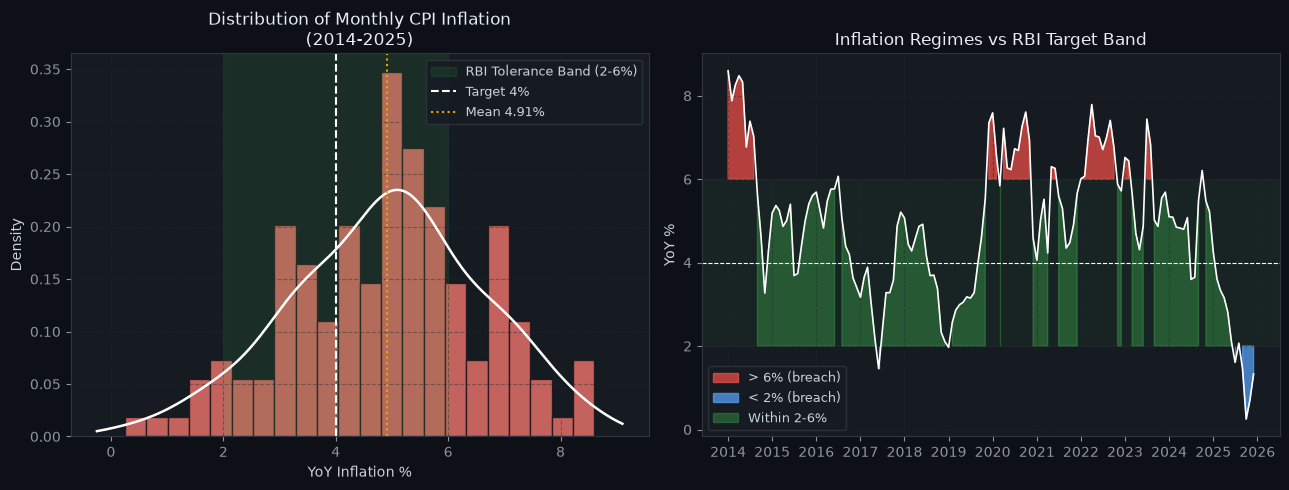

In [17]:
infl = cpi_e['c9'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.hist(infl, bins=22, color=COLORS['infl'], alpha=0.75, edgecolor='#0d1117', density=True)
kde2 = gaussian_kde(infl)
xs2  = np.linspace(infl.min()-0.5, infl.max()+0.5, 300)
ax.plot(xs2, kde2(xs2), color='white', lw=1.8)
ax.axvspan(2, 6, alpha=0.12, color='#3fb950', label='RBI Tolerance Band (2-6%)')
ax.axvline(4, color='white', lw=1.5, ls='--', label=f'Target 4%')
ax.axvline(infl.mean(), color='#f0a500', lw=1.5, ls=':', label=f'Mean {infl.mean():.2f}%')
ax.set_xlabel('YoY Inflation %'); ax.set_ylabel('Density')
ax.set_title('Distribution of Monthly CPI Inflation\n(2014-2025)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.4)

# Inflation regime timeline
ax = axes[1]
above6 = infl > 6; within = (infl>=2)&(infl<=6); below2 = infl < 2
ax.fill_between(infl.index, infl, 6, where=above6, color=COLORS['neg'],  alpha=0.7, label='> 6% (breach)')
ax.fill_between(infl.index, infl, 2, where=below2, color=COLORS['neutral'],alpha=0.7, label='< 2% (breach)')
ax.fill_between(infl.index, np.where(within,infl,np.nan), 2,
                where=within, color=COLORS['pos'], alpha=0.35, label='Within 2-6%')
ax.plot(infl.index, infl, color='white', lw=1.2)
ax.axhspan(2, 6, alpha=0.06, color='#3fb950')
ax.axhline(4, color='white', lw=0.8, ls='--')
ax.set_ylabel('YoY %'); ax.set_title('Inflation Regimes vs RBI Target Band')
ax.legend(fontsize=9); ax.grid(True, alpha=0.4)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/cpi_03_inflation_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 4. Cross-Variable Analysis

Now we analyse the **relationships between oil price, exchange rate, and CPI** — the three central
variables in the India inflation transmission mechanism.

**Theoretical channel:**  
`Global Oil Price (USD)` → `Import Cost in INR` = Oil × USD/INR → `Fuel CPI` → `Headline CPI`

In [18]:
# Build joint dataset
joint = pd.DataFrame({
    'oil_price':     oil_e['oil_price_usd_bbl'],
    'usd_inr':       fx_e['usd_inr'],
    'cpi_combined':  cpi_e['c8'],
    'cpi_inflation': cpi_e['c9'],
    'oil_inr':       oil_e['oil_price_usd_bbl'] * fx_e['usd_inr'],  # oil cost in INR/bbl
}).dropna()

joint['oil_ret']   = np.log(joint['oil_price']/joint['oil_price'].shift(1))*100
joint['fx_ret']    = np.log(joint['usd_inr']/joint['usd_inr'].shift(1))*100
joint['oil_inr_ret']= np.log(joint['oil_inr']/joint['oil_inr'].shift(1))*100

print('Joint dataset shape:', joint.shape)
print('Correlation matrix:')
print(joint[['oil_price','usd_inr','cpi_combined','cpi_inflation']].corr().round(3).to_string())

Joint dataset shape: (144, 8)
Correlation matrix:
               oil_price  usd_inr  cpi_combined  cpi_inflation
oil_price         1.0000   0.2280        0.2980         0.3130
usd_inr           0.2280   1.0000        0.9770        -0.1440
cpi_combined      0.2980   0.9770        1.0000        -0.1210
cpi_inflation     0.3130  -0.1440       -0.1210         1.0000


### 4.1 Correlation Heatmap

Pearson correlations between the four main series over 2014–2025.

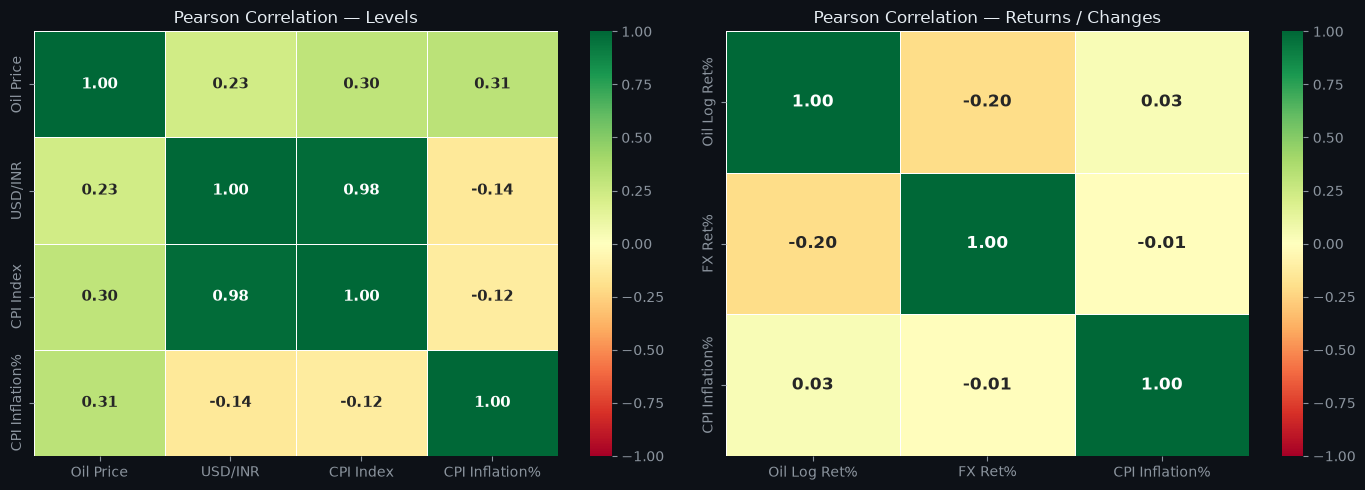

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Levels correlation
ax = axes[0]
corr_lvl = joint[['oil_price','usd_inr','cpi_combined','cpi_inflation']].corr()
corr_lvl.columns = ['Oil Price','USD/INR','CPI Index','CPI Inflation%']
corr_lvl.index   = corr_lvl.columns
mask = np.triu(np.ones_like(corr_lvl, dtype=bool), k=1)
sns.heatmap(corr_lvl, ax=ax, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, vmin=-1, vmax=1, linewidths=0.5,
            annot_kws={'size':11,'weight':'bold'})
ax.set_title('Pearson Correlation — Levels')

# Returns/changes correlation
ax = axes[1]
ret_cols = ['oil_ret','fx_ret','cpi_inflation']
corr_ret = joint[ret_cols].corr()
corr_ret.columns = ['Oil Log Ret%','FX Ret%','CPI Inflation%']
corr_ret.index   = corr_ret.columns
sns.heatmap(corr_ret, ax=ax, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, vmin=-1, vmax=1, linewidths=0.5,
            annot_kws={'size':12,'weight':'bold'})
ax.set_title('Pearson Correlation — Returns / Changes')

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/cross_01_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.2 Oil Price vs CPI Inflation — Scatter with Time Colour

Plotting oil price against CPI inflation for each month, coloured by year.
This shows whether higher oil prices **lead to higher inflation** — and how the relationship
may have changed across different macroeconomic regimes.

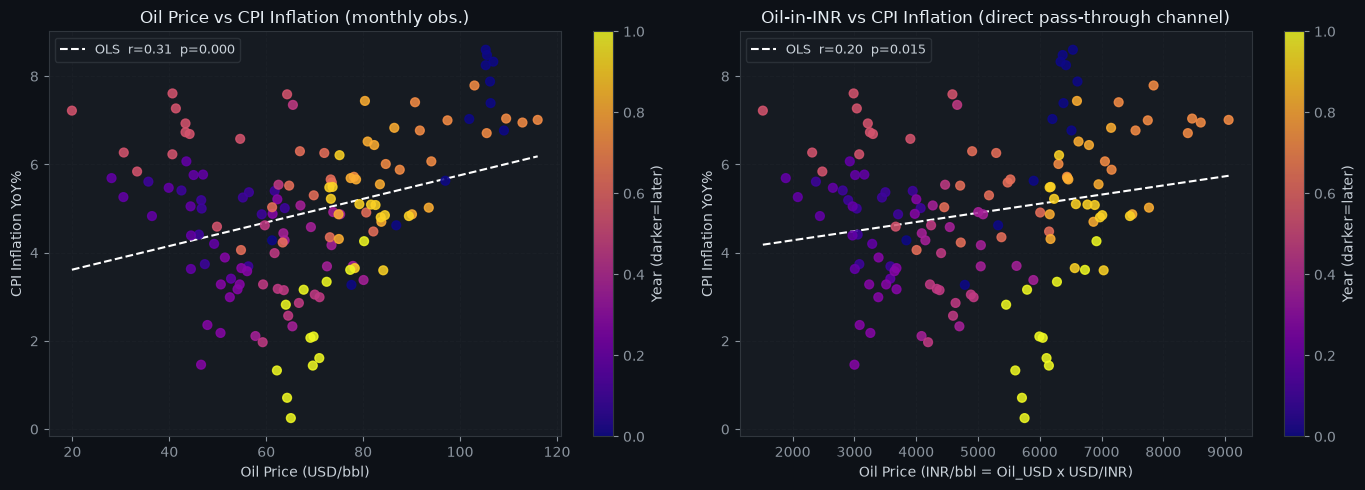

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cmap = plt.cm.plasma
years_norm = (joint.index.year - joint.index.year.min()) / \
             (joint.index.year.max() - joint.index.year.min())

# Oil price vs CPI inflation
ax = axes[0]
sc = ax.scatter(joint['oil_price'], joint['cpi_inflation'],
                c=years_norm, cmap=cmap, s=40, alpha=0.85, zorder=3)
m, b, r, p, _ = stats.linregress(joint['oil_price'].dropna(),
                                   joint['cpi_inflation'].dropna())
xs = np.linspace(joint['oil_price'].min(), joint['oil_price'].max(), 100)
ax.plot(xs, m*xs+b, color='white', lw=1.5, ls='--', label=f'OLS  r={r:.2f}  p={p:.3f}')
plt.colorbar(sc, ax=ax, label='Year (darker=later)')
ax.set_xlabel('Oil Price (USD/bbl)'); ax.set_ylabel('CPI Inflation YoY%')
ax.set_title('Oil Price vs CPI Inflation (monthly obs.)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.4)

# Oil price in INR vs CPI inflation (the more direct channel)
ax = axes[1]
sc2 = ax.scatter(joint['oil_inr'], joint['cpi_inflation'],
                 c=years_norm, cmap=cmap, s=40, alpha=0.85, zorder=3)
m2, b2, r2, p2, _ = stats.linregress(joint['oil_inr'].dropna(),
                                       joint['cpi_inflation'].dropna())
xs2 = np.linspace(joint['oil_inr'].min(), joint['oil_inr'].max(), 100)
ax.plot(xs2, m2*xs2+b2, color='white', lw=1.5, ls='--', label=f'OLS  r={r2:.2f}  p={p2:.3f}')
plt.colorbar(sc2, ax=ax, label='Year (darker=later)')
ax.set_xlabel('Oil Price (INR/bbl = Oil_USD x USD/INR)'); ax.set_ylabel('CPI Inflation YoY%')
ax.set_title('Oil-in-INR vs CPI Inflation (direct pass-through channel)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/cross_02_oil_vs_cpi_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.3 Oil Price vs USD/INR — The Import Cost Channel

A rising oil price puts pressure on India's current account deficit (CAD),
increasing demand for USD and weakening the INR. Conversely, a weak INR makes
oil imports more expensive even if the USD price is unchanged.

We examine both the **contemporaneous** and **lagged** relationship.

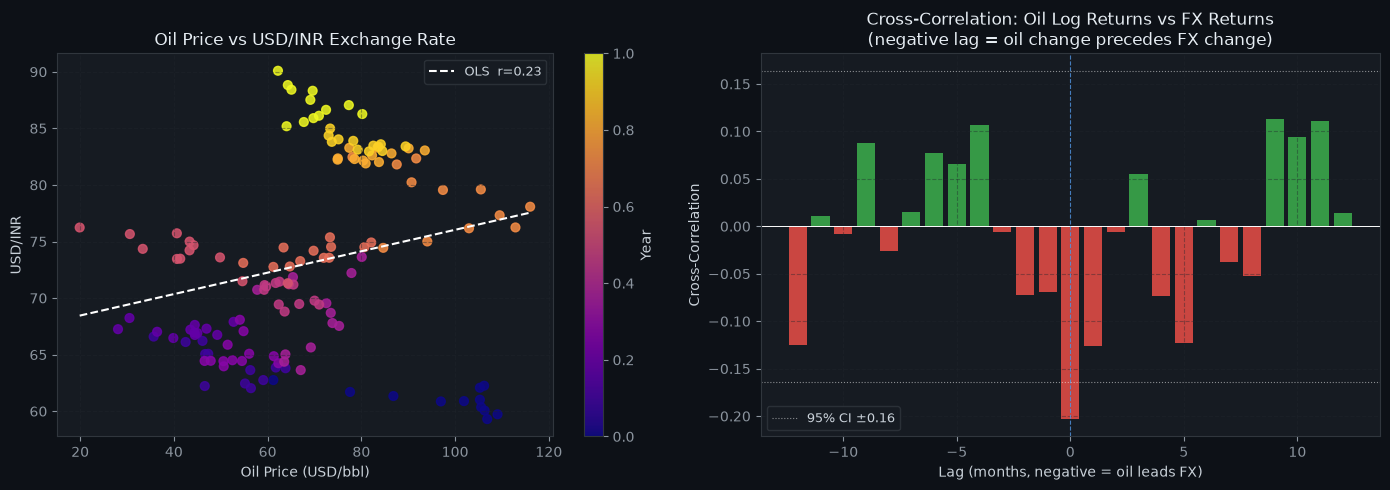

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter: oil vs USD/INR
ax = axes[0]
sc3 = ax.scatter(joint['oil_price'], joint['usd_inr'],
                 c=years_norm, cmap=cmap, s=40, alpha=0.85)
m3, b3, r3, p3, _ = stats.linregress(joint['oil_price'], joint['usd_inr'])
xs3 = np.linspace(joint['oil_price'].min(), joint['oil_price'].max(), 100)
ax.plot(xs3, m3*xs3+b3, color='white', lw=1.5, ls='--', label=f'OLS  r={r3:.2f}')
plt.colorbar(sc3, ax=ax, label='Year')
ax.set_xlabel('Oil Price (USD/bbl)'); ax.set_ylabel('USD/INR')
ax.set_title('Oil Price vs USD/INR Exchange Rate')
ax.legend(fontsize=9); ax.grid(True, alpha=0.4)

# Cross-correlation: oil returns vs FX returns at different lags
ax = axes[1]
max_lag = 12
lags = range(-max_lag, max_lag+1)
o = joint['oil_ret'].dropna(); f = joint['fx_ret'].dropna()
common = o.index.intersection(f.index)
o, f = o.loc[common], f.loc[common]
xcorrs = [o.corr(f.shift(lag)) for lag in lags]
colors_xcorr = [COLORS['pos'] if x>0 else COLORS['neg'] for x in xcorrs]
ax.bar(lags, xcorrs, color=colors_xcorr, alpha=0.8)
ax.axhline(0, color='white', lw=0.7)
ax.axvline(0, color='#58a6ff', lw=0.8, ls='--', alpha=0.7)
ci = 1.96/np.sqrt(len(common))
ax.axhline(ci,  color='white', lw=0.8, ls=':', alpha=0.5, label=f'95% CI ±{ci:.2f}')
ax.axhline(-ci, color='white', lw=0.8, ls=':', alpha=0.5)
ax.set_xlabel('Lag (months, negative = oil leads FX)')
ax.set_ylabel('Cross-Correlation')
ax.set_title('Cross-Correlation: Oil Log Returns vs FX Returns\n(negative lag = oil change precedes FX change)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/cross_03_oil_fx_channel.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.4 All Variables Together — Normalised Time Series

Plotting all three key series on a common normalised scale (Jan 2014 = 100) to compare
their relative movements and divergences over time.

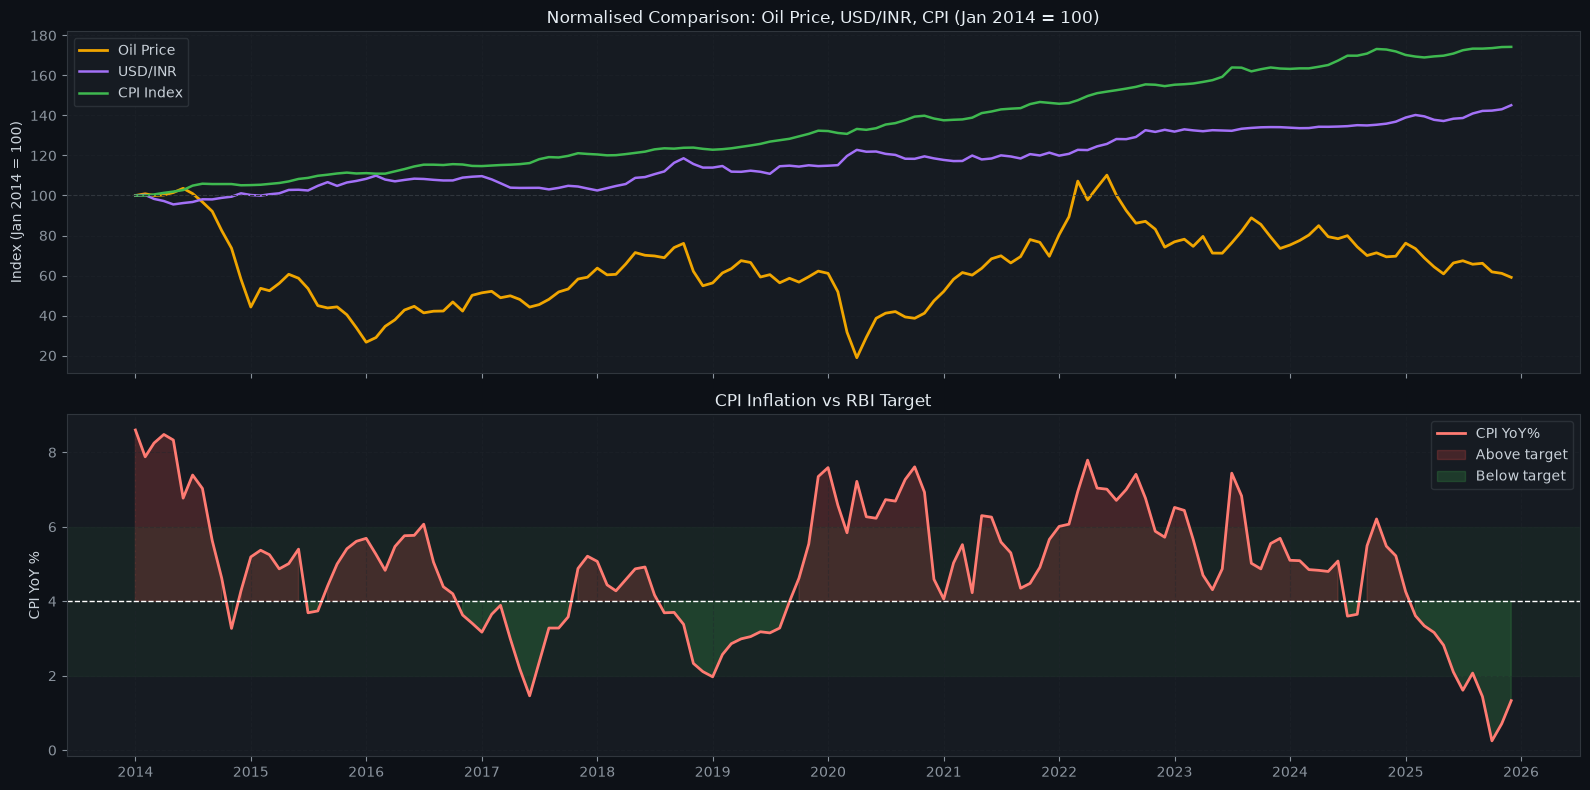

In [22]:
norm_base = joint.iloc[0]
joint_norm = (joint[['oil_price','usd_inr','cpi_combined']] / norm_base[['oil_price','usd_inr','cpi_combined']]) * 100

fig, (ax1,ax2) = plt.subplots(2,1, figsize=(16,8), sharex=True)

ax1.plot(joint_norm.index, joint_norm['oil_price'],  color=COLORS['oil'], lw=2,   label='Oil Price')
ax1.plot(joint_norm.index, joint_norm['usd_inr'],    color=COLORS['fx'],  lw=1.8, label='USD/INR')
ax1.plot(joint_norm.index, joint_norm['cpi_combined'],color=COLORS['cpi'], lw=1.8, label='CPI Index')
ax1.axhline(100, color='#30363d', lw=0.8, ls='--')
ax1.set_ylabel('Index (Jan 2014 = 100)')
ax1.set_title('Normalised Comparison: Oil Price, USD/INR, CPI (Jan 2014 = 100)')
ax1.legend(); ax1.grid(True, alpha=0.4)

ax2.plot(joint.index, joint['cpi_inflation'], color=COLORS['infl'], lw=2, label='CPI YoY%')
ax2.fill_between(joint.index, joint['cpi_inflation'], 4, alpha=0.2,
                 where=joint['cpi_inflation']>4, color=COLORS['neg'], label='Above target')
ax2.fill_between(joint.index, joint['cpi_inflation'], 4, alpha=0.2,
                 where=joint['cpi_inflation']<4, color=COLORS['pos'], label='Below target')
ax2.axhline(4, color='white', lw=1, ls='--')
ax2.axhspan(2,6, alpha=0.06, color='#3fb950')
ax2.set_ylabel('CPI YoY %'); ax2.set_title('CPI Inflation vs RBI Target')
ax2.legend(); ax2.grid(True, alpha=0.4)

for ax in [ax1,ax2]:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/cross_04_normalised_all.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 5. Summary of Key Findings

| # | Variable | Key Observation |
|---|----------|-----------------|
| 1 | **Oil Price** | High volatility with distinct regimes: 2014-16 collapse (OPEC no-cut), 2018 mini-cycle, 2020 COVID crash ($20/bbl), 2022 Ukraine War spike ($116/bbl). Distribution is right-skewed with heavy tails. |
| 2 | **Oil Seasonality** | Modest — prices tend slightly higher in Q1/Q2 of calendar year; the heatmap reveals regime-driven variation dominates over seasonality. |
| 3 | **USD/INR** | Structural depreciation trend: INR has lost ~45% of its Jan-2014 value vs USD over 2014-2025, at ~3-4% per year annualised. Volatility spikes during oil shocks (2018, 2020). |
| 4 | **CPI Inflation** | India's headline inflation spent the majority of 2014-2025 **above the 4% RBI target**. The 2022 episode breached the 6% upper tolerance. Food inflation is the dominant driver of volatility. |
| 5 | **Oil→CPI** | Weak-to-moderate contemporaneous correlation (r ≈ 0.2-0.4). The INR-adjusted oil cost (Oil × USD/INR) shows a slightly stronger relationship — confirming the FX pass-through channel. |
| 6 | **Oil→FX** | Cross-correlation shows a modest **leading relationship**: oil price changes tend to be followed by USD/INR changes 1-3 months later, consistent with trade balance / CAD dynamics. |

> **Note:** These are descriptive (EDA) findings. Causal inference requires controlling for confounders
(global growth, domestic demand, supply-side factors) — which is the purpose of the analysis
dataset built in `data_pipeline.ipynb`.

In [23]:
# List all saved output plots
import glob
plots = sorted(glob.glob(f'{OUT_DIR}/*.png'))
print(f'EDA plots saved to ./{OUT_DIR}/:')
for p in plots:
    size = os.path.getsize(p)
    print(f'  {os.path.basename(p):45s}  {size//1024:4d} KB')

EDA plots saved to ./eda_outputs/:
  cpi_01_headline_trend.png                       317 KB
  cpi_02_components.png                           434 KB
  cpi_03_inflation_distribution.png               177 KB
  cross_01_correlation.png                        104 KB
  cross_02_oil_vs_cpi_scatter.png                 234 KB
  cross_03_oil_fx_channel.png                     164 KB
  cross_04_normalised_all.png                     255 KB
  fx_01_usd_inr_trend.png                         181 KB
  fx_02_currencies_comparison.png                 200 KB
  fx_03_volatility.png                            174 KB
  oil_01_full_history.png                         161 KB
  oil_02_distribution.png                         144 KB
  oil_03_returns_volatility.png                   223 KB
  oil_04_seasonality.png                          156 KB
  oil_05_fy_averages.png                          117 KB
